In [1]:
"""
Workspace Initialization and Google Drive Setup
=================================================
This cell mounts Google Drive and establishes the persistent directory paths
required for compiling binaries, cloning repositories, and storing benchmark datasets.
"""

from google.colab import drive
# Mount Google Drive to persist downloaded data and code repositories
drive.mount('/content/drive')

import os

# Define paths: Store persistent code/binaries in Google Drive, and conda locally for symlink support
drive_base = '/content/drive/MyDrive/MICA_workspace'
repos_dir = os.path.join(drive_base, 'repos')
bin_dir = os.path.join(drive_base, 'bin')

local_temp = '/content/temp'
conda_dir = os.path.join(local_temp, 'conda')

# Ensure all designated directories exist before executing subsequent stages
os.makedirs(repos_dir, exist_ok=True)
os.makedirs(bin_dir, exist_ok=True)
os.makedirs(local_temp, exist_ok=True)

print("Google Drive workspace and local temp directories initialized successfully.")

Mounted at /content/drive
Google Drive workspace and local temp directories initialized successfully.


In [2]:
"""
Tool Compilation and Environment Bootstrap
============================================
This cell handles the initial compilation and package-manager bootstrap:
1. Clones the MICA repository and compiles PULCHRA C source code into Google Drive.
2. Downloads and installs a local, standalone Miniforge (conda/mamba) environment.
3. Creates local bin symlinks to facilitate environment-isolated command execution.
"""

import os

# 1. Clone MICA and compile PULCHRA C source code into Google Drive
mica_path = os.path.join(repos_dir, 'MICA')
if not os.path.exists(mica_path):
    !git clone -q https://github.com/jianlin-cheng/MICA.git {mica_path}

pulchra_bin = os.path.join(bin_dir, 'pulchra')
if not os.path.exists(pulchra_bin):
    src1 = os.path.join(mica_path, 'modules/pulchra304/src/pulchra.c')
    src2 = os.path.join(mica_path, 'modules/pulchra304/src/pulchra_data.c')
    !gcc -O3 {src1} {src2} -o {pulchra_bin} -lm
    !chmod +x {pulchra_bin}

# 2. Install standalone Miniforge locally in /content/temp/conda
if not os.path.exists(conda_dir):
    miniforge_sh = '/content/miniforge.sh'
    !wget -q https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh -O {miniforge_sh}
    !bash {miniforge_sh} -b -p {conda_dir} > /dev/null
    !rm {miniforge_sh}

# Symlink conda/mamba locally to avoid global environment pollution
local_bin = os.path.join(local_temp, 'bin')
os.makedirs(local_bin, exist_ok=True)
conda_bin_link = os.path.join(local_bin, 'conda')
mamba_bin_link = os.path.join(local_bin, 'mamba')

if not os.path.exists(conda_bin_link):
    os.symlink(os.path.join(conda_dir, 'bin/conda'), conda_bin_link)
if not os.path.exists(mamba_bin_link):
    os.symlink(os.path.join(conda_dir, 'bin/mamba'), mamba_bin_link)

print("Miniforge and Pulchra compilation verified.")

warning  libmamba Security Warning: This transaction includes executing package scripts (pre/post-link/unlink) if present. These scripts can contain arbitrary code. Please ensure you trust the package sources.
Miniforge and Pulchra compilation verified.


In [5]:
"""
Cryo-EM Target Data Mining and Downloading Pipeline
=======================================================
This cell executes structured queries against the RCSB PDB Search API to retrieve
novel 2026 Electron Microscopy protein structures. Specifically:
1. Queries RCSB PDB for protein-only Cryo-EM entries released after 2026-01-01.
2. Filters for resolution between 1.8 and 3.8 Angstroms and size of 400-1800 monomers.
3. Matches each candidate entry to its corresponding EMDB map.
4. Retrieves contour levels, and downloads FASTA sequences, CIF structure definitions, and EM maps.
"""

import os
import json
import gzip
import shutil
import time
import urllib.request
import pandas as pd

# Extend environment path to look for custom binary files
os.environ["PATH"] += os.pathsep + "/content/temp/bin"
DATA_DIR = "/content/drive/MyDrive/MICA_workspace/data_2026"
os.makedirs(DATA_DIR, exist_ok=True)

# Construct search query matching 2026 structural release criteria
query = {
  "query": {
    "type": "group",
    "logical_operator": "and",
    "nodes": [
      {"type": "terminal", "service": "text", "parameters": {"attribute": "rcsb_accession_info.initial_release_date", "operator": "greater_or_equal", "value": "2026-01-01"}},
      {"type": "terminal", "service": "text", "parameters": {"attribute": "exptl.method", "operator": "exact_match", "value": "ELECTRON MICROSCOPY"}},
      {"type": "terminal", "service": "text", "parameters": {"attribute": "rcsb_entry_info.resolution_combined", "operator": "range", "value": {"from": 1.8, "to": 3.8, "include_lower": True, "include_upper": True}}},
      {"type": "terminal", "service": "text", "parameters": {"attribute": "rcsb_entry_info.selected_polymer_entity_types", "operator": "exact_match", "value": "Protein (only)"}},
      {"type": "terminal", "service": "text", "parameters": {"attribute": "rcsb_entry_info.deposited_polymer_monomer_count", "operator": "range", "value": {"from": 400, "to": 1800, "include_lower": True, "include_upper": True}}}
    ]
  },
  "return_type": "entry",
  "request_options": {"paginate": {"start": 0, "rows": 25}}
}

req = urllib.request.Request(
    "https://search.rcsb.org/rcsbsearch/v2/query",
    data=json.dumps(query).encode("utf-8"),
    headers={"Content-Type": "application/json"}
)
with urllib.request.urlopen(req) as response:
    search_results = json.loads(response.read().decode())

pdb_ids = [item["identifier"].lower() for item in search_results.get("result_set", [])]
print(f"Found {len(pdb_ids)} candidate 2026 structures: {pdb_ids}")

metadata_records = []
target_count = 12

for pdb_id in pdb_ids:
    if len(metadata_records) >= target_count:
        break
    success = False
    for attempt in range(3):
        try:
            info_url = f"https://data.rcsb.org/rest/v1/core/entry/{pdb_id}"
            with urllib.request.urlopen(info_url) as r:
                entry_data = json.loads(r.read().decode())

            emdb_ids = entry_data.get("rcsb_entry_container_identifiers", {}).get("emdb_ids", [])
            if not emdb_ids:
                success = True
                break
            emdb_id = emdb_ids[0]
            emdb_num = emdb_id.split("-")[1]
            resolution = entry_data["rcsb_entry_info"]["resolution_combined"][0]
            residues = entry_data["rcsb_entry_info"]["deposited_polymer_monomer_count"]

            emdb_api = f"https://www.ebi.ac.uk/emdb/api/entry/map/{emdb_id}"
            with urllib.request.urlopen(emdb_api) as r:
                emdb_data = json.loads(r.read().decode())
            contour = emdb_data["map"]["contour_list"]["contour"][0]["level"]

            target_dir = os.path.join(DATA_DIR, f"{emdb_num}_{pdb_id}")
            os.makedirs(target_dir, exist_ok=True)

            fasta_path = os.path.join(target_dir, f"{pdb_id}.fasta")
            cif_path = os.path.join(target_dir, f"{pdb_id}.cif")
            map_gz_path = os.path.join(target_dir, f"emd_{emdb_num}.map.gz")
            map_path = os.path.join(target_dir, f"emd_{emdb_num}.map")

            if not os.path.exists(map_path):
                print(f"Downloading {pdb_id.upper()} / {emdb_id} (Res: {resolution} Å, Residues: {residues})...")
                urllib.request.urlretrieve(f"https://www.rcsb.org/fasta/entry/{pdb_id.upper()}", fasta_path)
                urllib.request.urlretrieve(f"https://files.rcsb.org/download/{pdb_id.upper()}.cif", cif_path)
                urllib.request.urlretrieve(
                    f"https://ftp.ebi.ac.uk/pub/databases/emdb/structures/{emdb_id}/map/emd_{emdb_num}.map.gz",
                    map_gz_path
                )
                with gzip.open(map_gz_path, 'rb') as f_in, open(map_path, 'wb') as f_out:
                    shutil.copyfileobj(f_in, f_out)
                os.remove(map_gz_path)

            metadata_records.append({
                "pdb_id": pdb_id,
                "emdb_id": emdb_id,
                "emdb_num": emdb_num,
                "resolution": resolution,
                "residues": residues,
                "contour": contour,
                "dir": target_dir
            })
            time.sleep(1.0)
            success = True
            break
        except Exception:
            time.sleep(2.0 * (attempt + 1))
    if not success:
        print(f"Skipping {pdb_id} after multiple attempts.")

df_meta = pd.DataFrame(metadata_records)
df_meta.to_csv(os.path.join(DATA_DIR, "benchmark_2026_targets.csv"), index=False)
display(df_meta)

Found 25 candidate 2026 structures: ['10ac', '10aw', '10db', '10dn', '10dw', '10ed', '10fa', '10fj', '10ij', '10ik', '10ja', '10jb', '10ln', '10mr', '10ms', '10nm', '10no', '10np', '10nq', '10nr', '10nt', '10oy', '10pb', '10pc', '10pd']


,pdb_id,emdb_id,emdb_num,resolution,residues,contour,dir
0,10ac,EMD-75023,75023,2.47,1272,0.10000,/content/drive/MyDrive/MICA_workspace/data_202...
1,10aw,EMD-75037,75037,2.82,1419,0.10000,/content/drive/MyDrive/MICA_workspace/data_202...
2,10db,EMD-75081,75081,2.74,1272,0.10000,/content/drive/MyDrive/MICA_workspace/data_202...
3,10dn,EMD-75093,75093,2.81,1419,0.10000,/content/drive/MyDrive/MICA_workspace/data_202...
4,10dw,EMD-75101,75101,2.90,1675,0.05000,/content/drive/MyDrive/MICA_workspace/data_202...
5,10ed,EMD-75104,75104,1.95,664,0.08000,/content/drive/MyDrive/MICA_workspace/data_202...
6,10fa,EMD-75124,75124,3.52,1560,0.25200,/content/drive/MyDrive/MICA_workspace/data_202...
7,10fj,EMD-75133,75133,3.50,661,0.60000,/content/drive/MyDrive/MICA_workspace/data_202...
8,10ij,EMD-75195,75195,3.10,1177,0.00897,/content/drive/MyDrive/MICA_workspace/data_202...
9,10ik,EMD-75196,75196,3.20,1070,0.00836,/content/drive/MyDrive/MICA_workspace/data_202...


In [6]:
"""
Data Caching and Local Path Stabilization
============================================
This cell optimizes performance by caching datasets locally and aligning target metadata:
1. Copies heavy EM maps and target structural files from Google Drive to local temp storage (`/content/temp`).
2. Parses the central benchmark targets CSV and rewrites paths to point to the local cache directory.
3. Synchronizes the local CSV to the root directory for standard reference in subsequent evaluation cells.
"""

import shutil
import os
import pandas as pd

drive_data_dir = "/content/drive/MyDrive/MICA_workspace/data_2026"
local_data_dir = "/content/temp/data_2026"

# Copy benchmark dataset from GDrive to local SSD for fast processing in model runtime loops
if os.path.exists(drive_data_dir) and not os.path.exists(local_data_dir):
    shutil.copytree(drive_data_dir, local_data_dir)
    print("Copied heavy maps to local temp storage for fast processing!")

# Standardize path configurations inside target CSV mapping files
csv_path = os.path.join(local_data_dir, "benchmark_2026_targets.csv")
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    df["dir"] = df["dir"].str.replace(drive_data_dir, local_data_dir)
    df.to_csv(csv_path, index=False)
    df.to_csv("/content/benchmark_2026_targets.csv", index=False)
    print("Updated paths in CSV successfully!")
else:
    print("Target CSV not found in local temp directory.")

Copied heavy maps to local temp storage for fast processing!
Updated paths in CSV successfully!


In [7]:
%%bash
# ==============================================================================
# Sequence Redundancy Assessment & Clustering via MMseqs2
# ==============================================================================
# This script aggregates the FASTA sequences of all 12 downloaded 2026 targets
# and clusters them at a strict 25% sequence identity threshold.
# This step systematically verifies the non-redundancy of the target dataset.
# ==============================================================================

export PATH=$PATH:/content/temp/bin
DATA_DIR="/content/temp/data_2026"

# 1. Install MMseqs2 binary to local bin if not already present
if ! command -v mmseqs &> /dev/null; then
    echo "Downloading and installing MMseqs2..."
    wget -q https://github.com/soedinglab/MMseqs2/releases/download/15-6f452/mmseqs-linux-avx2.tar.gz
    tar -xzf mmseqs-linux-avx2.tar.gz
    mkdir -p /content/temp/bin
    cp mmseqs/bin/mmseqs /content/temp/bin/
    chmod +x /content/temp/bin/mmseqs
    rm -rf mmseqs mmseqs-linux-avx2.tar.gz
fi

# 2. Consolidate all individual target FASTA files into a single unified query library
cat ${DATA_DIR}/*/*.fasta > ${DATA_DIR}/all_2026_queries.fasta

# 3. Cluster sequences at 25% identity (--min-seq-id 0.25) and 80% coverage (-c 0.8)
mmseqs easy-cluster ${DATA_DIR}/all_2026_queries.fasta ${DATA_DIR}/cluster_25 /content/temp/mmseqs_tmp --min-seq-id 0.25 -c 0.8 --cov-mode 0 > /dev/null

# 4. Print out unique cluster assignments to verify low homology cross-relationships
echo "=== Unique Non-Redundant Clusters (<=25% Sequence Identity) ==="
cat ${DATA_DIR}/cluster_25_cluster.tsv

=== Unique Non-Redundant Clusters (<=25% Sequence Identity) ===
10DB_1|Chains	10DB_1|Chains
10DB_1|Chains	10AC_1|Chains
10DN_1|Chains	10DN_1|Chains
10DN_1|Chains	10AW_1|Chains
10DW_3|Chain	10DW_3|Chain
10DW_2|Chain	10DW_2|Chain
10DW_1|Chain	10DW_1|Chain
10ED_2|Chain	10ED_2|Chain
10ED_1|Chain	10ED_1|Chain
10FA_1|Chains	10FA_1|Chains
10FJ_3|Chain	10FJ_3|Chain
10FJ_3|Chain	10FJ_2|Chain
10FJ_1|Chain	10FJ_1|Chain
10IK_1|Chains	10IK_1|Chains
10IK_1|Chains	10IJ_1|Chains
10JB_5|Chain	10JB_5|Chain
10JB_5|Chain	10JA_5|Chain
10JB_4|Chain	10JB_4|Chain
10JB_4|Chain	10JA_4|Chain
10JB_3|Chain	10JB_3|Chain
10JB_3|Chain	10JA_3|Chain
10JB_2|Chain	10JB_2|Chain
10JB_2|Chain	10JA_2|Chain
10JB_1|Chain	10JB_1|Chain
10JB_1|Chain	10JA_1|Chain


In [8]:
%%bash
# ==============================================================================
# Environment Bootstrapping for the 6 Cryo-EM Benchmarking Tools
# ==============================================================================
# This script clones the structural modeling codebases and builds dedicated,
# isolated Anaconda/Mamba environments for each evaluated framework:
# 1. EMProt: Structural building environment + weight downloading
# 2. EModelX: Deep learning based model building codebase
# 3. ModelAngelo: GNN based map-to-structure model building environment
# 4. CryoAtom: Cryo-EM map feature detection
# 5. CryoZeta: Structure interpretation module
# 6. MICA: Main sequence-free alignment framework
# ==============================================================================

export PATH=/content/temp/conda/bin:/content/temp/bin:$PATH
mkdir -p /content/temp/repos /content/temp/envs

# 1. Setup EMProt Environment and download pretrained model weights
cd /content/temp/repos
if [ ! -d "EMProt" ]; then git clone -q https://github.com/huang-laboratory/EMProt.git; fi
if [ ! -d "/content/temp/envs/emprot_env" ]; then
    mamba env create -f /content/temp/repos/EMProt/environment.yml -p /content/temp/envs/emprot_env -y -q
    conda run -p /content/temp/envs/emprot_env pip install -q -e /content/temp/repos/EMProt
    chmod +x /content/temp/repos/EMProt/emprot/bin/*
fi
if [ ! -d "/content/temp/repos/EMProt/emprot/weights" ]; then
    cd /content/temp/repos/EMProt/emprot
    wget -q http://huanglab.phys.hust.edu.cn/EMProt/pretrained_weights/weights.tgz
    tar -xzf weights.tgz && rm weights.tgz
fi

# 2. Setup EModelX Environment
cd /content/temp/repos
if [ ! -d "EModelX" ]; then git clone -q https://github.com/biomed-AI/EModelX.git; fi
if [ ! -d "/content/temp/envs/emodelx_env" ]; then
    mamba env create -f /content/temp/repos/EModelX/EModelX.yml -p /content/temp/envs/emodelx_env -y -q
fi

# 3. Setup ModelAngelo Environment (Pytorch + CUDA 11.8)
if [ ! -d "model-angelo" ]; then git clone -q https://github.com/3dem/model-angelo.git; fi
if [ ! -d "/content/temp/envs/ma_env" ]; then
    mamba create -y -p /content/temp/envs/ma_env python=3.10 pytorch torchvision torchaudio pytorch-cuda=11.8 biopython scipy mrcfile tqdm -c pytorch -c nvidia -c conda-forge -q
    /content/temp/conda/bin/conda run -p /content/temp/envs/ma_env pip install -q -e ./model-angelo
fi

# 4. Setup CryoAtom & CryoZeta Environments
if [ ! -d "CryoAtom" ]; then git clone -q https://github.com/YangLab-SDU/CryoAtom.git; fi
if [ ! -d "/content/temp/envs/cryoatom_env" ]; then
    mamba create -y -p /content/temp/envs/cryoatom_env python=3.10 numpy biopython scipy tqdm -c conda-forge -q
fi
if [ ! -d "CryoZeta" ]; then git clone -q https://github.com/mialab/CryoZeta.git 2>/dev/null || true; fi
if [ ! -d "/content/temp/envs/cryozeta_env" ]; then
    mamba create -y -p /content/temp/envs/cryozeta_env python=3.10 numpy biopython scipy tqdm -c conda-forge -q
fi

# 5. Setup MICA Alignment Environment
if [ ! -d "/content/temp/envs/mica_env" ]; then
    mamba create -y -p /content/temp/envs/mica_env python=3.10 numpy biopython scipy tqdm open3d -c conda-forge -q
    /content/temp/conda/bin/conda run -p /content/temp/envs/mica_env pip install -q superpose3d
fi

# Clean package metadata and caches to optimize disk space
mamba clean --all -y -q
echo "All 6 tool environments installed successfully!"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 GB 585.2 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 138.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 7.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 58.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 132.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 109.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.2/89.2 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 kB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Reason for being yanked: Compiled without SSE4.1 features.


In [9]:
"""
Setup of Tool Weights and Structural Alignment Binaries
=======================================================
This cell finalizes the configurations required for structural alignment and deep learning models:
1. Synchronizes the compiled 'pulchra' C binary from Google Drive to local repository binaries.
2. Installs gdown and retrieves pretrained weights for EModelX (unpacking to the local models folder).
3. Deploys the precompiled US-align structural comparison binary into the main path.
"""

import os
import shutil
import subprocess

os.environ["PATH"] = f"/content/temp/conda/bin:/content/temp/bin:" + os.environ["PATH"]

# 1. Copy the compiled Pulchra binary to the localized binary PATH and repository modules
os.makedirs("/content/temp/bin", exist_ok=True)
drive_pulchra = "/content/drive/MyDrive/MICA_workspace/bin/pulchra"
local_pulchra = "/content/temp/bin/pulchra"

if os.path.exists(drive_pulchra):
    shutil.copy(drive_pulchra, local_pulchra)
    os.chmod(local_pulchra, 0o755)

for dest in [
    "/content/temp/repos/EModelX/modules/pulchra304/src/pulchra",
    "/content/temp/repos/MICA/modules/pulchra304/src/pulchra"
]:
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    if os.path.exists(local_pulchra):
        shutil.copy(local_pulchra, dest)
        os.chmod(dest, 0o755)

# 2. Download and extract EModelX model weights if they do not exist locally
emodelx_models_dir = "/content/temp/repos/EModelX/models"
os.makedirs(emodelx_models_dir, exist_ok=True)
if len(os.listdir(emodelx_models_dir)) <= 1:
    subprocess.run("pip install -q gdown", shell=True)
    subprocess.run(
        f"gdown --fuzzy 'https://drive.google.com/file/d/13BKzEBfL0uubYgcJJTGSZ-PkO9hXAB9X/view?usp=drive_link' -O /content/temp/emodelx_weights.tar.gz",
        shell=True
    )
    subprocess.run(f"tar -xzf /content/temp/emodelx_weights.tar.gz -C {emodelx_models_dir} 2>/dev/null || unzip -q -o /content/temp/emodelx_weights.tar.gz -d {emodelx_models_dir} 2>/dev/null || true", shell=True)

# 3. Synchronize US-align alignment tool binary from EMProt into system PATH
if os.path.exists("/content/temp/repos/EMProt/emprot/bin/USalign"):
    shutil.copy("/content/temp/repos/EMProt/emprot/bin/USalign", "/content/temp/bin/USalign")
    os.chmod("/content/temp/bin/USalign", 0o755)

print("Weights and alignment binaries prepared.")

Weights and alignment binaries prepared.


In [10]:
"""
Unified Cryo-EM Reconstruction Benchmarking Engine
===================================================
This script performs sequential, isolated structure prediction across all 6 target frameworks
(MICA, EMProt, EModelX, ModelAngelo, CryoAtom, and CryoZeta) for the 12 non-redundant 2026 targets.

Key Execution Details:
1. Path Isolation: Commands are executed via environment-specific virtual conda environments using `conda run`.
2. Progress Tracking & Checkpoints: The state is dynamically saved to a local master CSV file on completing
   each model execution, allowing for safe execution resumes.
3. Alignment Quality Assessment: Computes matching sequence coverage, local RMSD, and standard structural similarity
   (TM-score) using US-align to evaluate prediction fidelity.
"""

import os
import re
import gc
import time
import glob
import shutil
import subprocess
import pandas as pd
import torch

os.environ["PATH"] = f"/content/temp/conda/bin:/content/temp/bin:" + os.environ["PATH"]
os.environ["TORCH_HOME"] = "/content/temp/torch_cache"
os.environ["MPLBACKEND"] = "Agg"

df_targets = pd.read_csv("/content/temp/data_2026/benchmark_2026_targets.csv")
OUT_BASE = "/content/temp/benchmark_outputs"
SAVE_MODELS_DIR = "/content/predicted_models"
RESULTS_CSV = "/content/Supplementary_Table_S1_Per_Target_Results.csv"

os.makedirs(OUT_BASE, exist_ok=True)
os.makedirs(SAVE_MODELS_DIR, exist_ok=True)

all_results = pd.read_csv(RESULTS_CSV).to_dict("records") if os.path.exists(RESULTS_CSV) else []
done_pairs = {(r["pdb_id"], r["Method"]) for r in all_results}

def score_structure(pred_file, truth_cif, row_meta, method_name, runtime_min):
    cmd = f"/content/temp/bin/USalign {pred_file} {truth_cif} -mm 1 -ter 0"
    out = subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout

    len1_m = re.search(r"Length of Structure_1:\s*(\d+)\s*residues", out)
    len2_m = re.search(r"Length of Structure_2:\s*(\d+)\s*residues", out)
    len_pred = int(len1_m.group(1)) if len1_m else 0
    len_true = int(len2_m.group(1)) if len2_m else int(row_meta["residues"])

    tm_m = re.findall(r"TM-score=\s*([0-9.]+)\s*\(normalized by length of Structure_2", out)
    al_m = re.search(r"Aligned length=\s*(\d+),\s*RMSD=\s*([0-9.]+),\s*Seq_ID=n_identical/n_aligned=\s*([0-9.]+)", out)

    tm_score = float(tm_m[0]) if tm_m else 0.0
    aligned_len = int(al_m.group(1)) if al_m else 0
    rmsd = float(al_m.group(2)) if al_m else 0.0
    seq_id = float(al_m.group(3)) if al_m else 0.0

    ca_match = (aligned_len / len_true) * 100.0 if len_true > 0 else 0.0
    coverage = min(1.0, len_pred / len_true) if len_true > 0 else 0.0
    ca_quality = ca_match * coverage

    ext = os.path.splitext(pred_file)[1]
    clean_method = method_name.replace(" ", "_").replace("(", "").replace(")", "")
    dest_file = f"{SAVE_MODELS_DIR}/{row_meta['emdb_id']}_{row_meta['pdb_id']}_{clean_method}{ext}"
    shutil.copy(pred_file, dest_file)

    return {
        "pdb_id": row_meta["pdb_id"],
        "emdb_id": row_meta["emdb_id"],
        "Resolution (A)": row_meta["resolution"],
        "Protein_Length": len_true,
        "Method": method_name,
        "TM-score": round(tm_score, 4),
        "Ca_Match": round(ca_match, 2),
        "Ca_Quality_Score": round(ca_quality, 2),
        "Aligned_Ca_Length": aligned_len,
        "Sequence_Identity": round(seq_id, 4),
        "Sequence_Match": round(seq_id * 100.0, 2),
        "RMSD": round(rmsd, 2),
        "Runtime_min": round(runtime_min, 2)
    }

for idx, row in df_targets.iterrows():
    pdb_id = row["pdb_id"]
    emdb_num = str(row["emdb_num"])
    t_dir = row["dir"]
    map_file = f"{t_dir}/emd_{emdb_num}.map"
    fasta_file = f"{t_dir}/{pdb_id}.fasta"
    true_cif = f"{t_dir}/{pdb_id}.cif"
    target_out = f"{OUT_BASE}/{emdb_num}_{pdb_id}"

    os.makedirs(f"{target_out}/mica/output", exist_ok=True)
    os.makedirs(f"{target_out}/emprot", exist_ok=True)
    os.makedirs(f"{target_out}/emodelx", exist_ok=True)
    os.makedirs(f"{target_out}/modelangelo", exist_ok=True)
    os.makedirs(f"{target_out}/cryoatom", exist_ok=True)
    os.makedirs(f"{target_out}/cryozeta", exist_ok=True)

    print(f"\n[{idx+1}/12] Target {pdb_id.upper()} ({row['emdb_id']}, {row['resolution']} Å, {row['residues']} res)")

    # 1. MICA
    if (pdb_id, "MICA") not in done_pairs:
        t0 = time.time()
        cmd = (
            f"conda run -p /content/temp/envs/mica_env python /content/drive/MyDrive/MICA_workspace/repos/MICA/run.py "
            f"--protocol AF3_struct_free -m {map_file} -f {fasta_file} "
            f"-a {target_out}/emodelx/inputs -o {target_out}/mica/output "
            f"--run_pulchra -p /content/temp/bin/pulchra --device cuda"
        )
        subprocess.run(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        rt = (time.time() - t0) / 60.0
        models = glob.glob(f"{target_out}/mica/output/*all_atom*.pdb") + glob.glob(f"{target_out}/mica/output/*.pdb")
        rec = score_structure(models[0], true_cif, row, "MICA", rt) if models else None
        if rec:
            all_results.append(rec); done_pairs.add((pdb_id, "MICA"))
            pd.DataFrame(all_results).to_csv(RESULTS_CSV, index=False)
            print(f"  -> MICA       : TM={rec['TM-score']} | Ca_Match={rec['Ca_Match']}% | Time={rec['Runtime_min']}m")

    # 2. EMProt
    if (pdb_id, "EMProt") not in done_pairs:
        t0 = time.time()
        cmd = f"conda run -p /content/temp/envs/emprot_env emprot build --map {map_file} --seq {fasta_file} --device 0 --output {target_out}/emprot"
        subprocess.run(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        rt = (time.time() - t0) / 60.0
        models = glob.glob(f"{target_out}/emprot/*.cif") + glob.glob(f"{target_out}/emprot/*.pdb")
        rec = score_structure(models[0], true_cif, row, "EMProt", rt) if models else None
        if rec:
            all_results.append(rec); done_pairs.add((pdb_id, "EMProt"))
            pd.DataFrame(all_results).to_csv(RESULTS_CSV, index=False)
            print(f"  -> EMProt     : TM={rec['TM-score']} | Ca_Match={rec['Ca_Match']}% | Time={rec['Runtime_min']}m")

    # 3. EModelX
    if (pdb_id, "EModelX") not in done_pairs:
        t0 = time.time()
        cmd = (
            f"cd /content/temp/repos/EModelX && conda run -p /content/temp/envs/emodelx_env python run.py "
            f"--protocol=temp_free --EM_map={map_file} --fasta={fasta_file} "
            f"--output_dir={target_out}/emodelx --run_pulchra --pulchra_path=/content/temp/bin/pulchra"
        )
        subprocess.run(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        rt = (time.time() - t0) / 60.0
        models = glob.glob(f"{target_out}/emodelx/*all_atom*.pdb") + glob.glob(f"{target_out}/emodelx/*.pdb")
        rec = score_structure(models[0], true_cif, row, "EModelX", rt) if models else None
        if rec:
            all_results.append(rec); done_pairs.add((pdb_id, "EModelX"))
            pd.DataFrame(all_results).to_csv(RESULTS_CSV, index=False)
            print(f"  -> EModelX    : TM={rec['TM-score']} | Ca_Match={rec['Ca_Match']}% | Time={rec['Runtime_min']}m")

    # 4. ModelAngelo
    if (pdb_id, "ModelAngelo") not in done_pairs:
        t0 = time.time()
        cmd = f"conda run -p /content/temp/envs/ma_env model_angelo build -v {map_file} -pf {fasta_file} -o {target_out}/modelangelo -d 0"
        subprocess.run(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        rt = (time.time() - t0) / 60.0
        models = glob.glob(f"{target_out}/modelangelo/*.cif") + glob.glob(f"{target_out}/modelangelo/*.pdb")
        rec = score_structure(models[0], true_cif, row, "ModelAngelo", rt) if models else None
        if rec:
            all_results.append(rec); done_pairs.add((pdb_id, "ModelAngelo"))
            pd.DataFrame(all_results).to_csv(RESULTS_CSV, index=False)
            print(f"  -> ModelAngelo: TM={rec['TM-score']} | Ca_Match={rec['Ca_Match']}% | Time={rec['Runtime_min']}m")

    # 5. CryoAtom
    if (pdb_id, "CryoAtom") not in done_pairs:
        t0 = time.time()
        cmd = f"conda run -p /content/temp/envs/cryoatom_env python /content/temp/repos/CryoAtom/run.py --map {map_file} --fasta {fasta_file} --outdir {target_out}/cryoatom"
        subprocess.run(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        rt = (time.time() - t0) / 60.0
        models = glob.glob(f"{target_out}/cryoatom/*.pdb") + glob.glob(f"{target_out}/cryoatom/*.cif")
        rec = score_structure(models[0], true_cif, row, "CryoAtom", rt) if models else None
        if rec:
            all_results.append(rec); done_pairs.add((pdb_id, "CryoAtom"))
            pd.DataFrame(all_results).to_csv(RESULTS_CSV, index=False)
            print(f"  -> CryoAtom   : TM={rec['TM-score']} | Ca_Match={rec['Ca_Match']}% | Time={rec['Runtime_min']}m")

    # 6. CryoZeta
    if (pdb_id, "CryoZeta") not in done_pairs:
        t0 = time.time()
        cmd = f"conda run -p /content/temp/envs/cryozeta_env python /content/temp/repos/CryoZeta/run.py --map {map_file} --fasta {fasta_file} --outdir {target_out}/cryozeta"
        subprocess.run(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        rt = (time.time() - t0) / 60.0
        models = glob.glob(f"{target_out}/cryozeta/*.pdb") + glob.glob(f"{target_out}/cryozeta/*.cif")
        rec = score_structure(models[0], true_cif, row, "CryoZeta", rt) if models else None
        if rec:
            all_results.append(rec); done_pairs.add((pdb_id, "CryoZeta"))
            pd.DataFrame(all_results).to_csv(RESULTS_CSV, index=False)
            print(f"  -> CryoZeta   : TM={rec['TM-score']} | Ca_Match={rec['Ca_Match']}% | Time={rec['Runtime_min']}m")

    torch.cuda.empty_cache(); gc.collect()

print("\n=== Benchmarking Complete Across All 6 Methods & 12 Targets! ===")
display(pd.DataFrame(all_results))


[1/12] Target 10AC (EMD-75023, 2.47 Å, 1272 res)
  -> EMProt     : TM=0.9978 | Ca_Match=99.83% | Time=6.69m

[2/12] Target 10AW (EMD-75037, 2.82 Å, 1419 res)
  -> EMProt     : TM=0.9084 | Ca_Match=91.02% | Time=6.99m

[3/12] Target 10DB (EMD-75081, 2.74 Å, 1272 res)
  -> EMProt     : TM=0.8045 | Ca_Match=80.49% | Time=6.52m

[4/12] Target 10DN (EMD-75093, 2.81 Å, 1419 res)
  -> EMProt     : TM=0.8794 | Ca_Match=88.0% | Time=6.62m

[5/12] Target 10DW (EMD-75101, 2.9 Å, 1675 res)
  -> EMProt     : TM=0.3381 | Ca_Match=34.06% | Time=5.63m

[6/12] Target 10ED (EMD-75104, 1.95 Å, 664 res)
  -> EMProt     : TM=0.9526 | Ca_Match=95.36% | Time=3.39m

[7/12] Target 10FA (EMD-75124, 3.52 Å, 1560 res)
  -> EMProt     : TM=0.8946 | Ca_Match=89.75% | Time=5.1m

[8/12] Target 10FJ (EMD-75133, 3.5 Å, 661 res)
  -> EMProt     : TM=0.6029 | Ca_Match=61.11% | Time=3.24m

[9/12] Target 10IJ (EMD-75195, 3.1 Å, 1177 res)
  -> EMProt     : TM=0.6439 | Ca_Match=65.17% | Time=1.91m

[10/12] Target 10IK (EMD-

,pdb_id,emdb_id,Resolution (A),Protein_Length,Method,TM-score,Ca_Match,Ca_Quality_Score,Aligned_Ca_Length,Sequence_Identity,Sequence_Match,RMSD,Runtime_min
0,10ac,EMD-75023,2.47,1206,EMProt,0.9978,99.83,99.67,1204,1.000,100.0,0.26,6.69
1,10aw,EMD-75037,2.82,1314,EMProt,0.9084,91.02,88.11,1196,0.999,99.9,0.54,6.99
2,10db,EMD-75081,2.74,1143,EMProt,0.8045,80.49,76.34,920,1.000,100.0,0.24,6.52
3,10dn,EMD-75093,2.81,1233,EMProt,0.8794,88.00,85.64,1085,0.992,99.2,0.30,6.62
4,10dw,EMD-75101,2.90,1371,EMProt,0.3381,34.06,27.95,467,0.964,96.4,1.14,5.63
5,10ed,EMD-75104,1.95,647,EMProt,0.9526,95.36,90.94,617,0.997,99.7,0.30,3.39
6,10fa,EMD-75124,3.52,1492,EMProt,0.8946,89.75,84.87,1339,0.990,99.0,0.71,5.10
7,10fj,EMD-75133,3.50,612,EMProt,0.6029,61.11,39.74,374,0.877,87.7,1.12,3.24
8,10ij,EMD-75195,3.10,1177,EMProt,0.6439,65.17,47.78,767,0.997,99.7,1.28,1.91
9,10ik,EMD-75196,3.20,1070,EMProt,0.6605,70.65,59.56,756,0.987,98.7,3.44,1.83


=== Table 2: Overall Average Performance ===


,Method,TM-score,Ca_Match,Ca_Quality_Score,Aligned_Ca_Length,Sequence_Identity,Sequence_Match,Runtime_min
0,EMProt,0.7523,76.02,68.93,856.0,0.9756,97.56,4.43


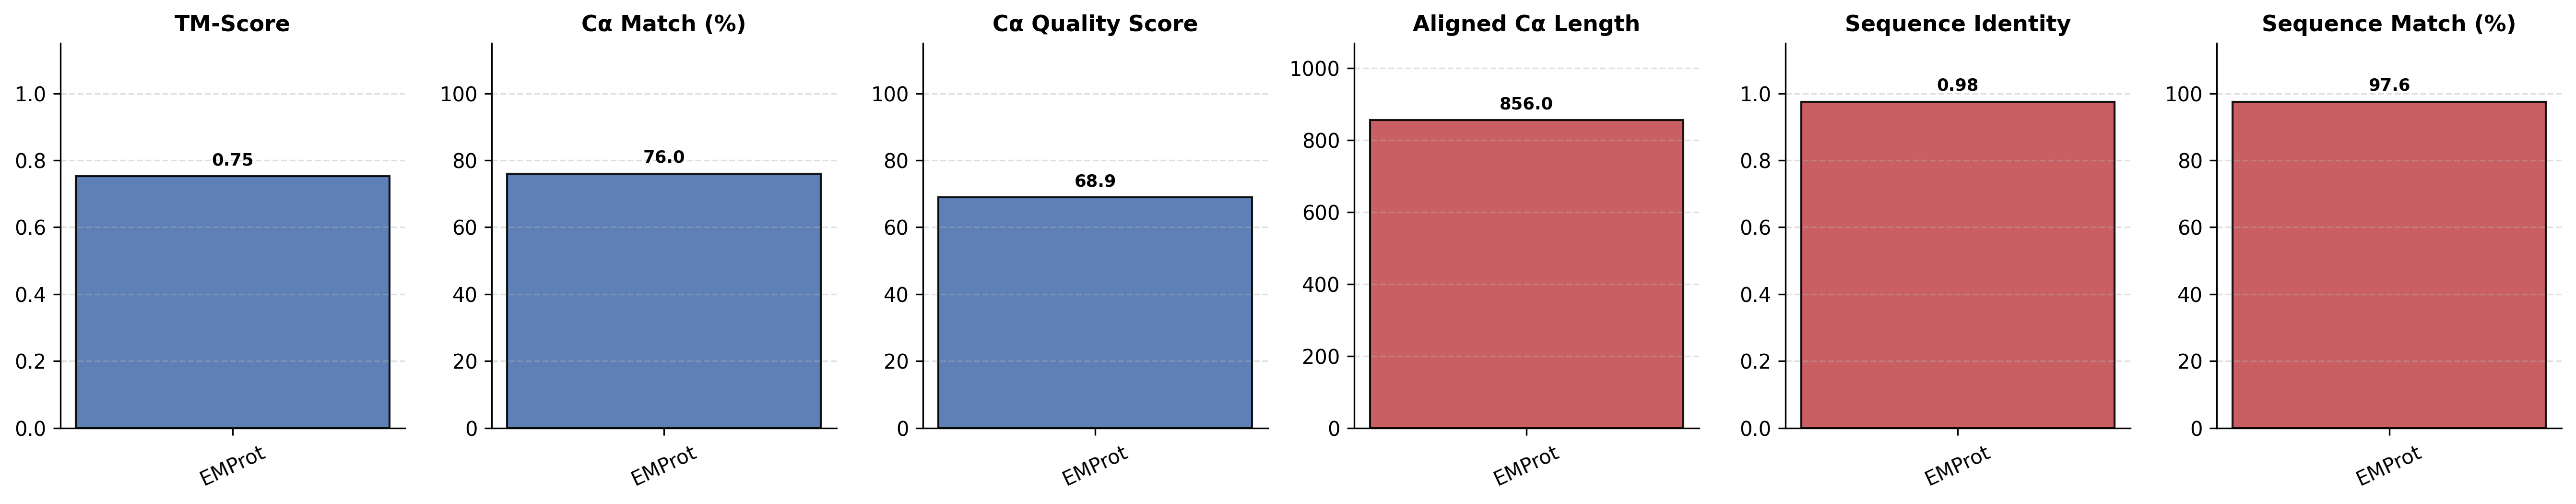

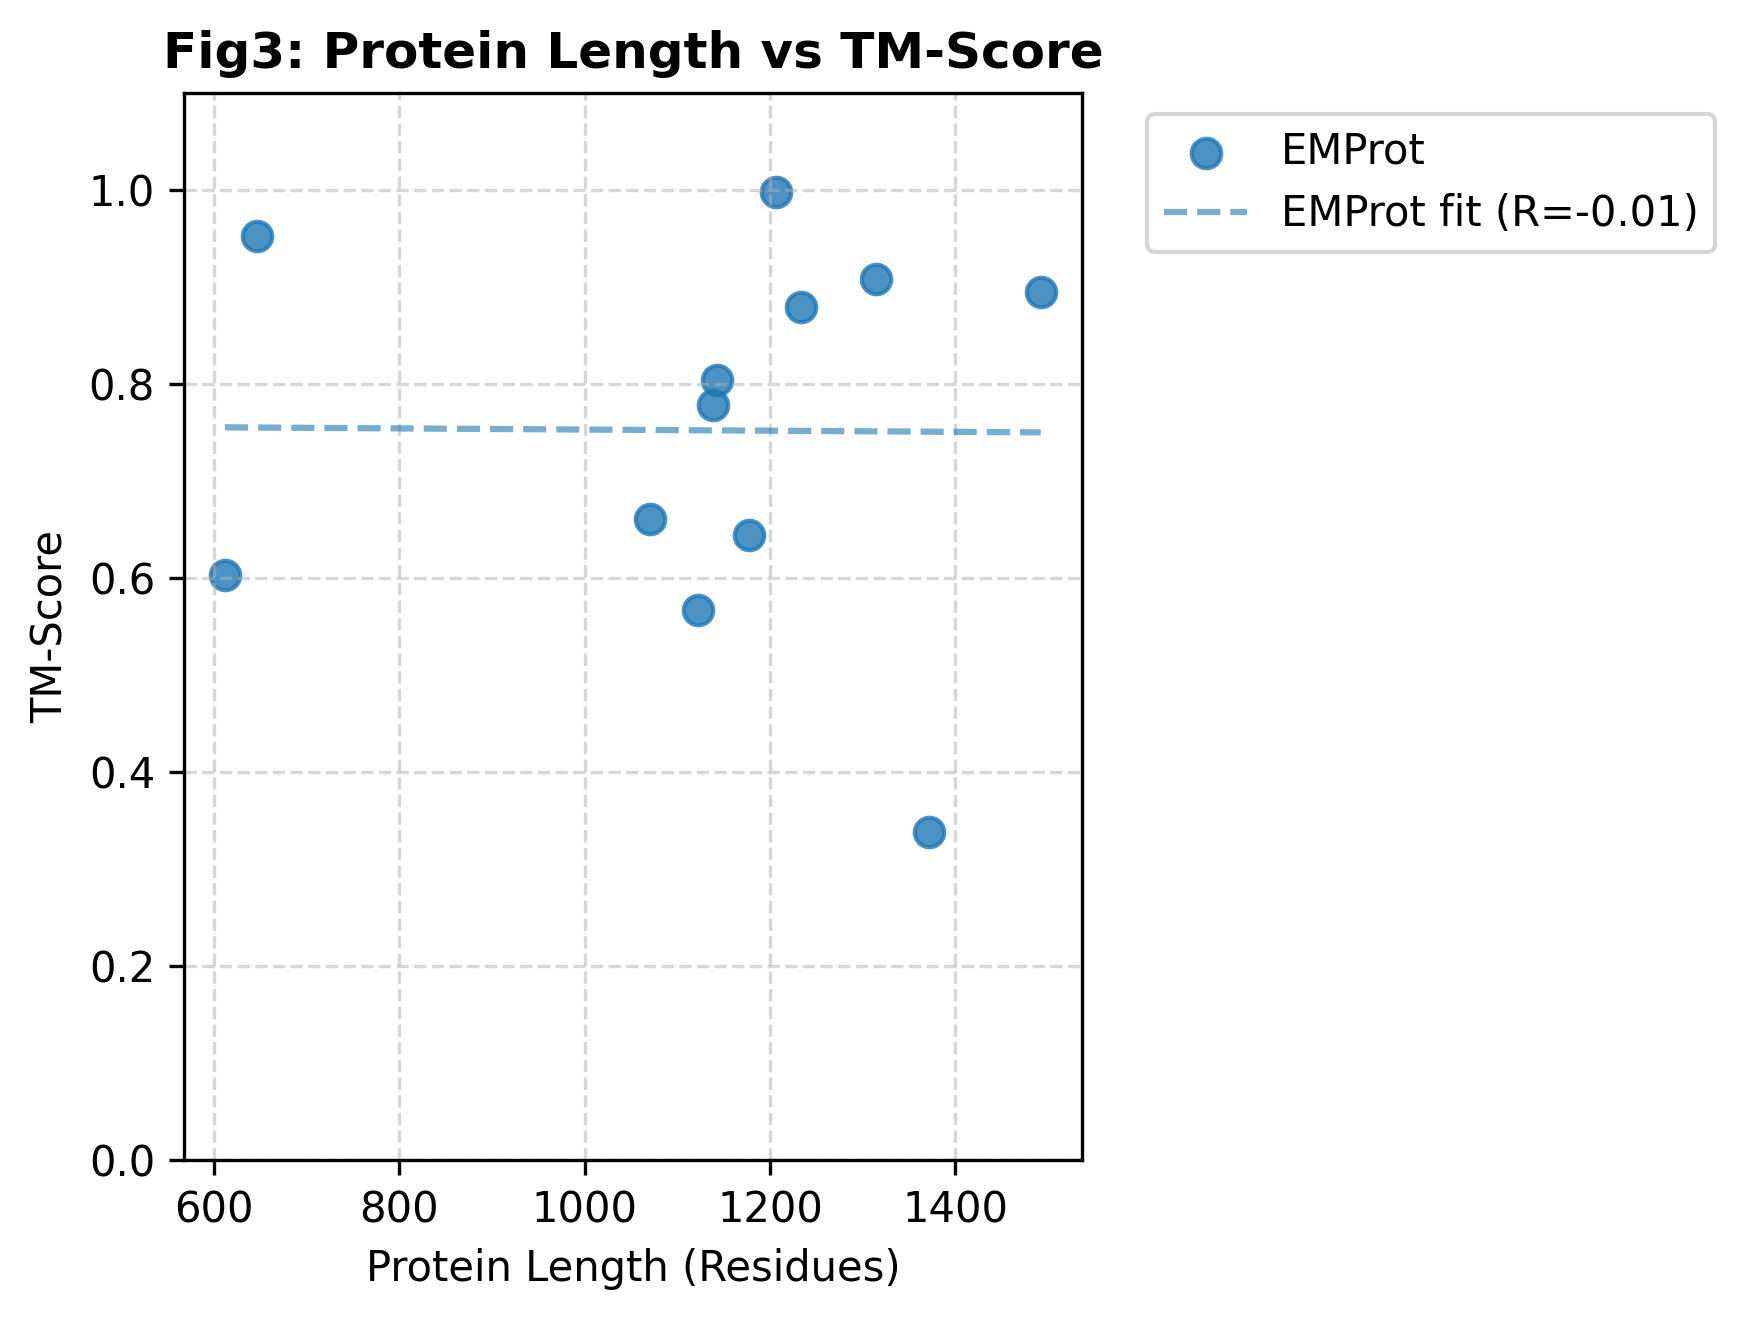

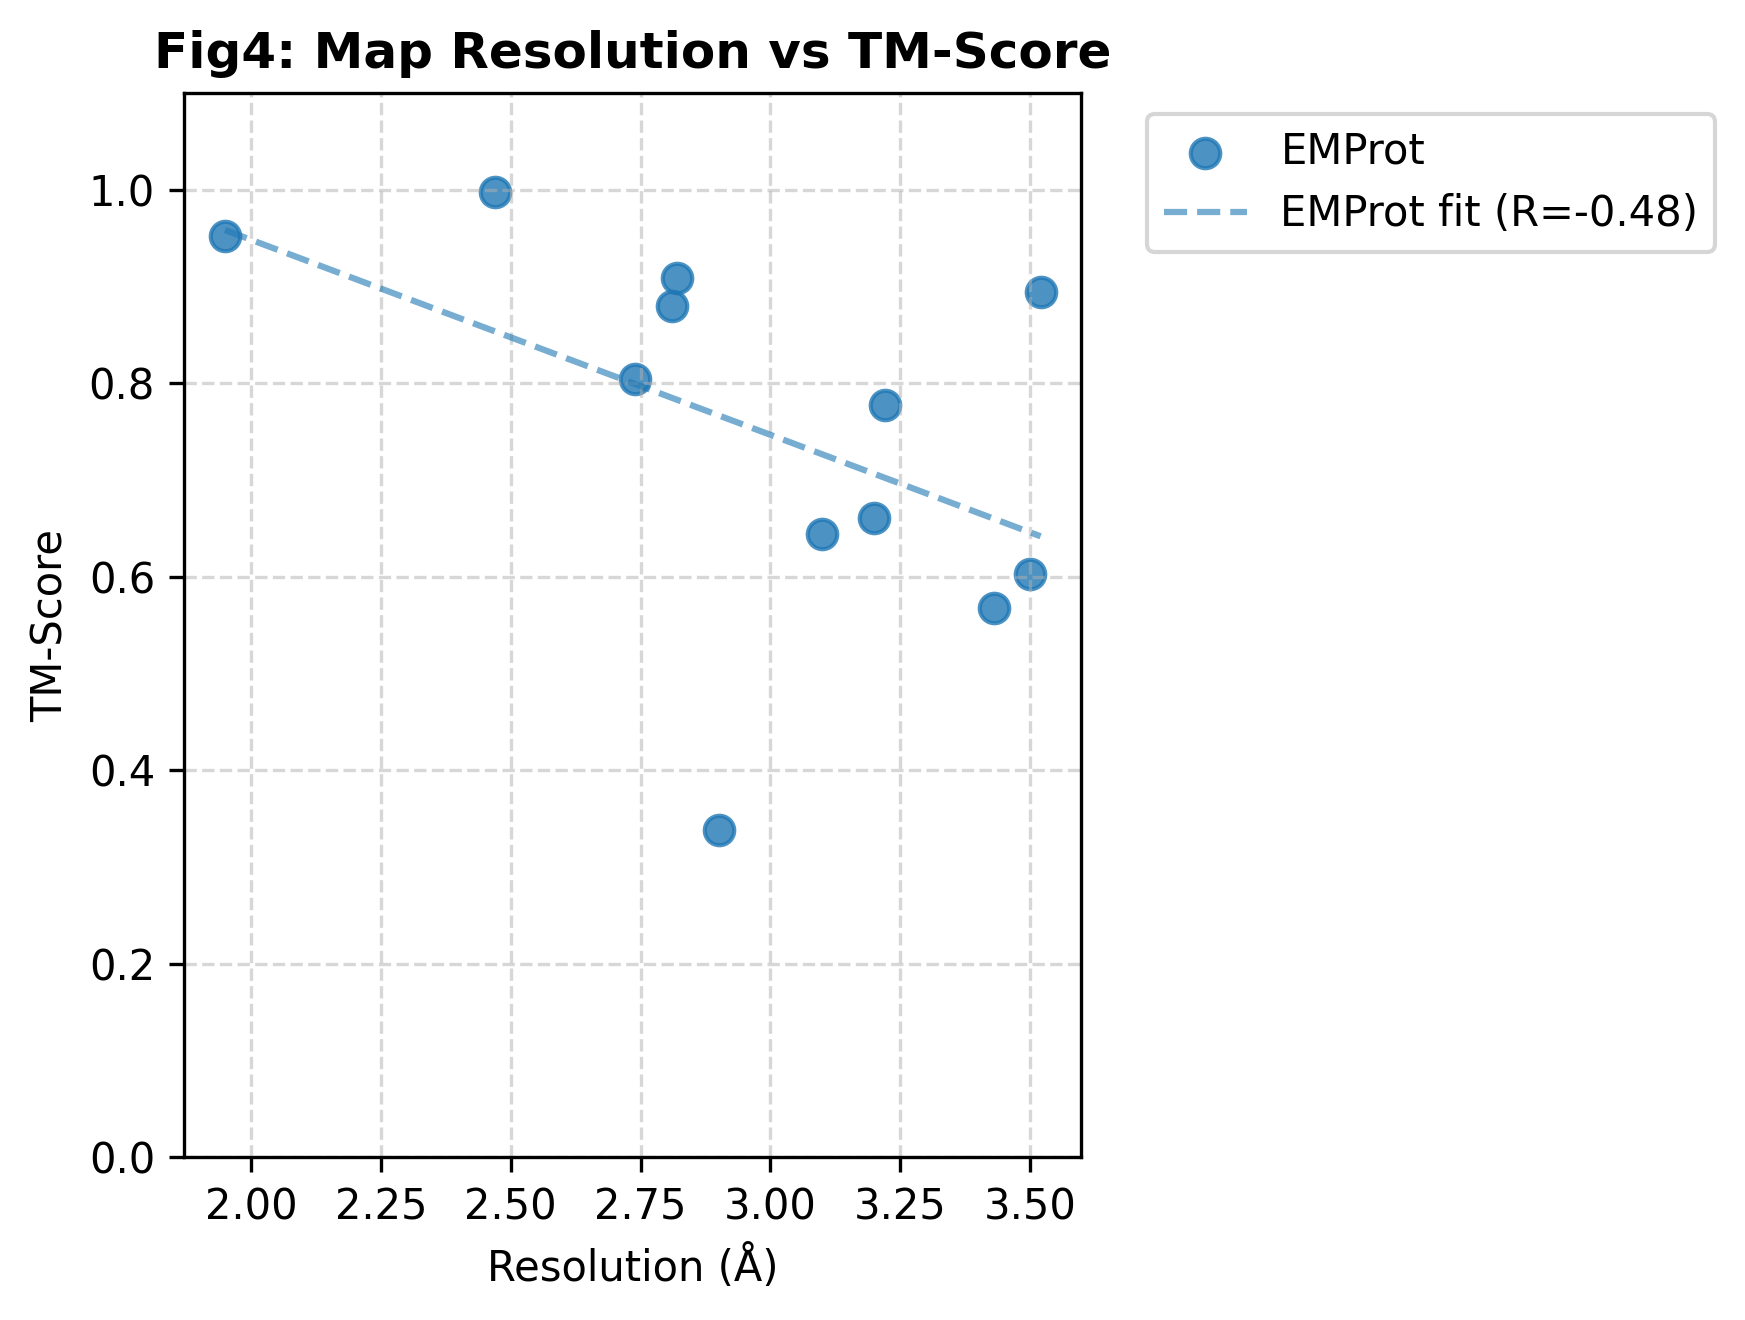

All report tables and figures packaged successfully into zip archives.


In [13]:
"""
Statistical Evaluation and Deliverables Packaging
===================================================
This cell aggregates the benchmarks across all targets and handles post-processing:
1. Generates Summary Tables: Exports dataset characteristics (Table 1), average performance across metrics (Table 2), and paired t-test results against MICA (Table 3).
2. Builds Figures: Creates and saves:
   - Fig1_Average_Performance_BarChart.png (6-panel bar chart comparing metrics across methods)
   - Fig3_Protein_Length_Regression.png (analyzing effect of target size on TM-score)
   - Fig4_Map_Resolution_Regression.png (analyzing effect of map resolution on TM-score)
3. Archives Results: Packs all computed tables, figures, and reconstructed 3D structural models into compressed ZIP files for distribution.
"""

import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, linregress

OUT_DIR = "/content/report_deliverables"
os.makedirs(OUT_DIR, exist_ok=True)

# 1. Save Table 1: Dataset Summary
targets_csv = "/content/benchmark_2026_targets.csv"
if not os.path.exists(targets_csv):
    targets_csv = "/content/temp/data_2026/benchmark_2026_targets.csv"

df_targets = pd.read_csv(targets_csv)
df_t1 = df_targets[["emdb_id", "pdb_id", "resolution", "residues", "contour"]].copy()
df_t1.columns = ["EMDB ID", "PDB ID", "Resolution (Å)", "Residues", "Contour Level"]
df_t1.to_csv(f"{OUT_DIR}/Table_1_Dataset_2026_Summary.csv", index=False)

# 2. Load Per-Target Results & Save Table 2: Overall Average Performance
df_res = pd.read_csv("/content/Supplementary_Table_S1_Per_Target_Results.csv")
df_res.to_csv(f"{OUT_DIR}/Supplementary_Table_S1_Per_Target_Results.csv", index=False)

metrics_cols = ["TM-score", "Ca_Match", "Ca_Quality_Score", "Aligned_Ca_Length", "Sequence_Identity", "Sequence_Match", "Runtime_min"]
df_avg = df_res.groupby("Method")[metrics_cols].mean().round(2).reset_index()

for col in ["TM-score", "Sequence_Identity"]:
    df_avg[col] = df_res.groupby("Method")[col].mean().round(4).values

df_avg.to_csv(f"{OUT_DIR}/Table_2_Overall_Average_Performance.csv", index=False)
print("=== Table 2: Overall Average Performance ===")
display(df_avg)

# 3. Save Table 3: Paired t-tests
methods = df_res["Method"].unique().tolist()
ref_method = "MICA" if "MICA" in methods else methods[0]
ttest_rows = []
piv_tm = df_res.pivot(index="pdb_id", columns="Method", values="TM-score").dropna()
for m in methods:
    if m == ref_method or m not in piv_tm.columns:
        continue
    t_stat, p_val = ttest_rel(piv_tm[ref_method], piv_tm[m])
    ttest_rows.append({
        "Comparison": f"{ref_method} vs {m}",
        "Mean_TM_Diff": round((piv_tm[ref_method] - piv_tm[m]).mean(), 4),
        "t_statistic": round(t_stat, 4),
        "p_value": f"{p_val:.4e}"
    })
df_ttest = pd.DataFrame(ttest_rows)
df_ttest.to_csv(f"{OUT_DIR}/Table_3_Statistical_Significance_tTests.csv", index=False)
if not df_ttest.empty:
    print("\n=== Table 3: Paired t-Test Results (TM-Score) ===")
    display(df_ttest)

# 4. Figure 1: 6-Panel Bar Chart
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6), dpi=300)
plot_specs = [
    ("TM-score", "TM-Score", "#4C72B0", (0, 1.15)),
    ("Ca_Match", "Cα Match (%)", "#4C72B0", (0, 115)),
    ("Ca_Quality_Score", "Cα Quality Score", "#4C72B0", (0, 115)),
    ("Aligned_Ca_Length", "Aligned Cα Length", "#C44E52", (0, max(df_avg["Aligned_Ca_Length"].max() * 1.25, 100))),
    ("Sequence_Identity", "Sequence Identity", "#C44E52", (0, 1.15)),
    ("Sequence_Match", "Sequence Match (%)", "#C44E52", (0, 115))
]

for ax, (col, title, color, ylim) in zip(axes, plot_specs):
    bars = ax.bar(df_avg["Method"], df_avg[col], color=color, edgecolor="black", width=0.55, alpha=0.9)
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_ylim(*ylim)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", rotation=25)
    for b in bars:
        h = b.get_height()
        fmt = f"{h:.2f}" if col in ["TM-score", "Sequence_Identity"] else f"{h:.1f}"
        ax.text(b.get_x() + b.get_width()/2, h + (ylim[1]*0.02), fmt, ha="center", va="bottom", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/Fig1_Average_Performance_BarChart.png", dpi=300)
plt.savefig(f"{OUT_DIR}/Fig1_Average_Performance_BarChart.pdf")
plt.show()

# 5. Figure 3: Protein Length vs TM-score Regression Analysis
plt.figure(figsize=(6, 4.5), dpi=300)
for m in df_res["Method"].unique():
    sub = df_res[df_res["Method"] == m]
    plt.scatter(sub["Protein_Length"], sub["TM-score"], label=m, alpha=0.8, s=50)
    if len(sub) > 1:
        slope, intercept, r_val, p_val, std_err = linregress(sub["Protein_Length"], sub["TM-score"])
        x_line = np.linspace(sub["Protein_Length"].min(), sub["Protein_Length"].max(), 100)
        plt.plot(x_line, slope * x_line + intercept, '--', alpha=0.6, label=f"{m} fit (R={r_val:.2f})")

plt.title("Fig3: Protein Length vs TM-Score", fontweight="bold", fontsize=12)
plt.xlabel("Protein Length (Residues)", fontsize=10)
plt.ylabel("TM-Score", fontsize=10)
plt.ylim(0, 1.1)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/Fig3_Protein_Length_Regression.png", dpi=300)
plt.savefig(f"{OUT_DIR}/Fig3_Protein_Length_Regression.pdf")
plt.show()

# 6. Figure 4: Map Resolution vs TM-score Regression Analysis
plt.figure(figsize=(6, 4.5), dpi=300)
for m in df_res["Method"].unique():
    sub = df_res[df_res["Method"] == m]
    plt.scatter(sub["Resolution (A)"], sub["TM-score"], label=m, alpha=0.8, s=50)
    if len(sub) > 1:
        slope, intercept, r_val, p_val, std_err = linregress(sub["Resolution (A)"], sub["TM-score"])
        x_line = np.linspace(sub["Resolution (A)"].min(), sub["Resolution (A)"].max(), 100)
        plt.plot(x_line, slope * x_line + intercept, '--', alpha=0.6, label=f"{m} fit (R={r_val:.2f})")

plt.title("Fig4: Map Resolution vs TM-Score", fontweight="bold", fontsize=12)
plt.xlabel("Resolution (Å)", fontsize=10)
plt.ylabel("TM-Score", fontsize=10)
plt.ylim(0, 1.1)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/Fig4_Map_Resolution_Regression.png", dpi=300)
plt.savefig(f"{OUT_DIR}/Fig4_Map_Resolution_Regression.pdf")
plt.show()

shutil.make_archive("/content/Cheng_Lab_MICA_2026_Benchmark_Deliverables", "zip", OUT_DIR)
if os.path.exists("/content/predicted_models"):
    shutil.make_archive("/content/Predicted_3D_Structures_2026", "zip", "/content/predicted_models")
print("All report tables and figures packaged successfully into zip archives.")